# 影片前處理：SigLIP 2 Video Encoder
流程：影片 → 鏡頭切分 → 4 fps 擷取影格 → SigLIP 2 逐格編碼 → pooling → 每支影片一個向量
輸出：`features/video/{DATA_MODE}_{MODEL_TAG}.pt`，主 notebook 的 2.3 Video Encoder 直接讀取

**為什麼另開一本 notebook？**
1. 影片解碼與編碼最花時間，只需跑一次
2. 需要的套件（PySceneDetect、OpenCV）跟主模型無關
3. 快取以 `media_id` 命名，pilot 算過的影片，full 模式可以直接沿用

**和 MM-AU（§6.1）的對照**

| 步驟 | MM-AU | 本專案 |
|---|---|---|
| 鏡頭切分 | PySceneDetect | 同，ContentDetector |
| 影格擷取 | 4 fps | 同，每支上限 480 格 |
| 影格編碼 | CLIP ViT-B/32 | SigLIP 2 base-patch16-**naflex** |
| 影格 → 鏡頭 | average pool | 同 |
| 鏡頭 → 影片 | 無（鏡頭序列直接進 LSTM / Transformer） | **固定 32 格再 max-pool**（理由見第 10 節） |

# 0. 匯入與參數

| 參數 | 設定 | 為什麼 |
|---|---|---|
| `SAMPLE_FPS` | 4 | 照 MM-AU §6.1 |
| `MAX_FRAMES` | 480 | = 120 秒 × 4 fps。抽樣的 50 支影片最長 120 秒、75 百分位 70 秒。原本設 360，超過 90 秒的影片會改成均勻抽格，取樣密度就跟其他影片不一樣；改成 480 後，全部影片都維持 4 fps |
| `SIGLIP_MODEL` | naflex | 96% 是 9:16 直式。正方形輸入的版本，不是把畫面壓扁，就是把上下的字卡裁掉。NaFlex 保留原始長寬比，SigLIP 2 論文指出它在 OCR、文件類 benchmark 多半比較好 |
| `MAX_PATCHES` | 256 | 9:16 約 12×21 個 patch（約 192×336 px）。576 能看清更多畫面文字，但運算量約 2.5 倍，留作 ablation |
| `RESIZE_LONG` | 512 | 主流解析度 720×1280，讀進來先縮小，省記憶體；NaFlex 實際只用到約 336 px，不損失資訊 |
| `SCENE_THRESHOLD` / `MIN_SCENE_SEC` | 27 / 0.5 秒 | MM-AU 沒寫，用 PySceneDetect 預設值。Reels 剪接快，限制最短 0.5 秒，確保每個鏡頭至少抽得到一格 |
| `FIXED_K` | 32 | 每支影片均勻取 32 格再 max，消除「格數越多、最大值越高」的偏誤（見第 10 節） |
| `MAX_SHOTS` | 35 | 照 MM-AU；只影響存下的鏡頭序列，不影響 pooling 向量 |
| `RUN_SCENE_DETECT` | True | pilot 保留鏡頭資訊，供 SPoD 整合時測試 attention pooling；若無效，full 資料集改 False |

> 論文沒有寫、自己決定的參數，在程式碼註解標了「← MM-AU 未給」或「← 自訂」

In [1]:
# 若尚未安裝：pip install "scenedetect[opencv]" "transformers>=4.49"
import warnings, random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoModel, AutoProcessor
from scenedetect import open_video, SceneManager, ContentDetector
import matplotlib.pyplot as plt

In [2]:
# ── 資料模式 ──
DATA_MODE = "pilot"        # "pilot" / "full"

ROOT      = Path("/home/yingtzudai/Multimodal_SPoD_Video")
SPLIT_CSV = {"pilot": ROOT / "data/split/pilot_posts.csv",
             "full":  ROOT / "data/split/post_split.csv"}[DATA_MODE]
DATA_ROOT = Path("/home/ftp_246/data_5/多模態2026_ig_top200")
VIDEO_DIR = DATA_ROOT / "Video_data_fullest/ig_vedios"          # {username}/{stem}.mp4
FEAT_DIR  = ROOT / "features"

SEED   = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE  = torch.float16 if device.type == "cuda" else torch.float32
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── 鏡頭切分（MM-AU：PySceneDetect）──
RUN_SCENE_DETECT = True    # full 資料集若 attention pooling 未證實有用，改 False，省下一次完整解碼
SCENE_THRESHOLD = 27.0     # ContentDetector 預設值 ← MM-AU 未給
MIN_SCENE_SEC   = 0.5      # 最短鏡頭長度          ← MM-AU 未給

# ── 影格擷取（MM-AU：4 fps）──
SAMPLE_FPS  = 4
MAX_FRAMES  = 480          # 最多480格，超過約120秒則均勻取樣(因Pilot video最常者只有約120秒)
RESIZE_LONG = 512          # 讀進來先把長邊縮到 512，省記憶體（NaFlex 實際只用到約 336px）

# ── SigLIP 2 ──
SIGLIP_MODEL = "google/siglip2-base-patch16-naflex"   # ablation："google/siglip2-base-patch16-224"
MAX_PATCHES  = 256 # NaFlex 序列長度；MAX_PATCHES = 256 是每張影像的 patch 數量預算。對 9:16 影像，理想化的網格可能接近 12×21，但實際配置應以 processor 的輸出為準。
FRAME_BATCH  = 32
PROC_KW = {"max_num_patches": MAX_PATCHES} if "naflex" in SIGLIP_MODEL else {}

# ── Pooling / 序列 ──
FIXED_K   = 32             # 每支影片均勻取 K 格再 max（消除格數造成的極值效應）
POOLS     = ["max_k", "mean_shot", "mean_frame", "max"]   # 第一個是預設，其餘為 ablation
MAX_SHOTS = 35

# ── 存檔 ──
MODEL_TAG = (SIGLIP_MODEL.split("/")[-1]
             + (f"_p{MAX_PATCHES}" if PROC_KW else "") + f"_fps{SAMPLE_FPS}")
CACHE_DIR = FEAT_DIR / "video" / "cache" / MODEL_TAG   # 每支影片一個檔，pilot / full 共用
OUT_PT    = FEAT_DIR / "video" / f"{DATA_MODE}_{MODEL_TAG}.pt"
SAVE_FRAME_EMB = True      # 保留逐格 embedding，之後換 pooling 不用重算
RECOMPUTE      = False
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(device, "|", MODEL_TAG)

cuda | siglip2-base-patch16-naflex_p256_fps4


# 1. 貼文清單與影片路徑

In [3]:
posts = pd.read_csv(SPLIT_CSV, dtype={"media_id": str, "stem": str})
posts["media_id"]   = posts["media_id"].str.strip()
posts["video_path"] = [VIDEO_DIR / u / f"{s}.mp4" for u, s in zip(posts["username"], posts["stem"])]
posts["has_video"]  = posts["video_path"].map(Path.exists)

print(posts.shape, "| 找得到影片的比例：", posts["has_video"].mean().round(3))
print(posts.loc[~posts["has_video"], ["username", "stem"]].head())

(299, 9) | 找得到影片的比例： 1.0
Empty DataFrame
Columns: [username, stem]
Index: []


In [4]:
assert posts["media_id"].notna().all(), "有缺少 media_id 的貼文"
assert posts["media_id"].is_unique, "media_id 有重複，請先檢查"

assert posts["username"].notna().all()
assert posts["stem"].notna().all()

# 2. 影片格式檢查
只讀檔頭、不解碼，很快。用來決定 `MAX_FRAMES`、`RESIZE_LONG`。

**抽樣結果（n = 50）**
- fps：23.98–30，大多是 30
- 解析度：主流 720×1280，最小 360×640
- 長度：中位數 44.7 秒，75 百分位 70.5 秒，最長 120.3 秒
- 直式比例 96%；4 fps 下平均每支 198 格

**為什麼不排除 outlier（橫式、極短、很長的影片）？**
1. **避免選擇偏誤**：SPoD 要對所有貼文排序，實際使用時一定會遇到這些影片
2. **格式本身可能是訊號**：橫式可能是品牌提供的廣告素材；長度也跟業配有關（業配中位數 59.9 秒，非業配 37.1 秒）
3. **流程本身能處理**：NaFlex 不會讓橫式變形；最短的影片也有約 35 格；pooling 後每支都是同樣維度的向量

真正排除的只有技術上壞掉的檔案，而且不刪資料，只標成 `video_ok = False`，當作「缺少影片模態」。

In [5]:
def probe(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        return None
    fps = cap.get(cv2.CAP_PROP_FPS)
    n   = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    w, h = cap.get(cv2.CAP_PROP_FRAME_WIDTH), cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    cap.release()
    return {"fps": fps, "n_frames": n, "width": w, "height": h,
            "duration": n / fps if fps else np.nan}

sample = posts[posts["has_video"]].sample(min(50, posts["has_video"].sum()), random_state=SEED)
info = pd.DataFrame([probe(p) or {} for p in sample["video_path"]])
print(info.describe().T.round(2))
print("直式比例：", (info["height"] > info["width"]).mean().round(3))
print("4 fps 下平均每支影格數：", (info["duration"] * SAMPLE_FPS).mean().round(0))

          count     mean     std     min      25%      50%      75%      max
fps        50.0    29.76    1.19   23.98    30.00    30.00    30.00    30.00
n_frames   50.0  1476.32  886.87  261.00   725.25  1301.00  2115.50  3610.00
width      50.0   716.80  108.07  360.00   720.00   720.00   720.00  1280.00
height     50.0  1232.00  164.83  640.00  1280.00  1280.00  1280.00  1280.00
duration   50.0    49.45   29.44    8.70    24.18    44.66    70.52   120.33
直式比例： 0.96
4 fps 下平均每支影格數： 198.0


In [6]:
# 全部影片都讀一次檔頭，結果併回 posts
info_all = pd.DataFrame([probe(p) if ok else {} for p, ok in zip(posts["video_path"], posts["has_video"])],
                        index=posts.index)
posts = posts.drop(columns=info_all.columns, errors="ignore").join(info_all)   # 重跑時先移除舊欄位
posts["orient"] = np.where(posts["height"] > posts["width"], "portrait",
                  np.where(posts["height"] < posts["width"], "landscape", "square"))
posts["dur_bin"] = pd.cut(posts["duration"], [0, 15, 30, 60, 90, np.inf],
                          labels=["<15s", "15-30s", "30-60s", "60-90s", ">90s"])

print("讀不到 / 長度 < 1 秒：", int(((posts["duration"] < 1) | posts["duration"].isna()).sum()), "支")
print("\n各方向的業配比例")
print(posts.groupby("orient")["label"].agg(["mean", "count"]).round(3))
print("\n各長度區間的業配比例")
print(posts.groupby("dur_bin", observed=True)["label"].agg(["mean", "count"]).round(3))
print("\n超過 MAX_FRAMES 上限、會改為均勻抽格的比例：",
      (posts["duration"] * SAMPLE_FPS > MAX_FRAMES).mean().round(3))

# print(posts.columns)

讀不到 / 長度 < 1 秒： 0 支

各方向的業配比例
            mean  count
orient                 
landscape  0.600      5
portrait   0.454    293
square     0.000      1

各長度區間的業配比例
          mean  count
dur_bin              
<15s     0.211     38
15-30s   0.227     44
30-60s   0.419    124
60-90s   0.750     64
>90s     0.621     29

超過 MAX_FRAMES 上限、會改為均勻抽格的比例： 0.047


上面結果顯示，影片越長，業配的比例越高，也因此後面要留意影片長度問題，避免因此洩露label

**全部 299 支的結果**
- 讀不到或長度不足 1 秒：0 支
- 業配比例隨長度上升：<15 秒 21%、30–60 秒 42%、60–90 秒 75% → 長度是很強的訊號，第 10 節要處理
- 橫式 5 支、正方形 1 支：樣本太少，不做結論
- 4.7% 超過 2 分鐘，改為均勻抽格

# 3. 鏡頭切分（PySceneDetect）
- 用 `ContentDetector`：比較相鄰畫面的色彩差異，差異超過門檻就算換鏡頭
- 一鏡到底的影片 → 整支當成一個鏡頭

**檢查結果（pilot）**：鏡頭數中位數 13、最多 122；每秒最多 1.19 個鏡頭，沒有發現閃光或字卡被大量誤判，門檻不用調整。

In [7]:
def detect_shots(path, fps, duration):
    video = open_video(str(path))
    sm = SceneManager()
    sm.add_detector(ContentDetector(threshold=SCENE_THRESHOLD,
                                    min_scene_len=max(1, int(MIN_SCENE_SEC * fps))))
    sm.detect_scenes(video, show_progress=False)
    scenes = sm.get_scene_list(start_in_scene=True)
    shots = [(s.seconds, e.seconds) for s, e in scenes]
    return shots or [(0.0, duration)]          # 一鏡到底 → 整支當一個鏡頭

# 抽 3 支看切得合不合理（可對照影片手動檢查）
for p in sample["video_path"].head(3):
    i = probe(p)
    s = detect_shots(p, i["fps"], i["duration"])
    print(p.name, f"{i['duration']:.1f}s →", len(s), "個鏡頭", [round(a, 1) for a, _ in s][:10])

thetiffanychen-20251228211256-1216903180549089.mp4 94.6s → 50 個鏡頭 [0.0, 5.4, 6.6, 7.3, 7.9, 8.6, 13.4, 15.4, 16.9, 18.7]
1_shiuan_0-20250908004431-1635094370996640.mp4 51.7s → 13 個鏡頭 [0.0, 10.3, 16.4, 18.1, 34.6, 35.9, 38.6, 44.3, 46.5, 47.7]
zoebitalk-20250630230332-1492024018951094.mp4 13.8s → 11 個鏡頭 [0.0, 5.6, 6.4, 7.1, 7.7, 8.5, 9.4, 10.1, 10.7, 11.8]


# 4. 影格擷取（4 fps）
- 依序讀每一格，只解碼需要的那幾格（`grab` / `retrieve`），比用 `CAP_PROP_POS_MSEC` 跳著讀更準
- 用影片自己的 fps 換算時間，23.98 fps 這種非整數也能算對
- 超過 480 格（約 2 分鐘）才改成均勻抽格

In [8]:
def sample_frames(path, fps, n_frames):
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError(f"影片 FPS 無效：{fps}")

    if not np.isfinite(n_frames) or n_frames < 1:
        raise ValueError(f"影格數無效：{n_frames}")
    
    duration = n_frames / fps
    times = np.arange(0, duration, 1 / SAMPLE_FPS)
    if len(times) > MAX_FRAMES:
        times = np.linspace(0, duration, MAX_FRAMES, endpoint=False)
    targets = set(np.minimum(np.round(times * fps).astype(int), int(n_frames) - 1).tolist())
    last = max(targets)

    cap, frames, ts, i = cv2.VideoCapture(str(path)), [], [], 0
    while i <= last and cap.grab():
        if i in targets:
            ok, img = cap.retrieve()
            if ok:
                h, w = img.shape[:2]
                s = RESIZE_LONG / max(h, w)
                if s < 1:
                    img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
                frames.append(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
                ts.append(i / fps)
        i += 1
    cap.release()
    return frames, np.array(ts)

# 5. SigLIP 2 影格 embedding
- `get_image_features` 拿到的是 MAP head（attention pooling）的輸出。SigLIP 沒有 [CLS]，這就是整張圖的代表向量，base 版 768 維
- 每格先做 **L2 normalize**：SigLIP 是在 cosine 空間訓練的，先 normalize 再平均或取最大，比較合理
- 對照組：`google/siglip2-base-patch16-224`（正方形輸入）。SigLIP 2 論文指出，B 尺寸在自然影像上標準版比 NaFlex 好，所以留作 ablation

In [9]:
processor = AutoProcessor.from_pretrained(SIGLIP_MODEL)
siglip = AutoModel.from_pretrained(SIGLIP_MODEL, torch_dtype=DTYPE).to(device).eval()

@torch.no_grad()
def encode_frames(frames):
    out = []
    for i in range(0, len(frames), FRAME_BATCH):
        inputs = processor(images=frames[i:i + FRAME_BATCH], return_tensors="pt", **PROC_KW).to(device)
        inputs["pixel_values"] = inputs["pixel_values"].to(DTYPE)
        e = siglip.get_image_features(**inputs)
        if not torch.is_tensor(e):              # 新版 transformers 可能回傳 output 物件
            e = e.pooler_output
        out.append(F.normalize(e.float(), dim=-1).cpu())
    return torch.cat(out)                       # (影格數, d)；base = 768

EMB_DIM = siglip.config.vision_config.hidden_size
print("EMB_DIM:", EMB_DIM)

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

EMB_DIM: 768


# 6. Pooling：影格 → 鏡頭 → 影片

| 名稱 | 做法 | 角色 |
|---|---|---|
| `max_k` | 均勻取 32 格，每一維取最大值 | **預設** |
| `mean_shot` | 先平均成鏡頭，再平均所有鏡頭（每個鏡頭等權） | ablation |
| `mean_frame` | 所有影格直接平均（等於依時長加權） | ablation |
| `max` | 所有影格取最大值（SPoD 的 image max-pool） | ablation：會混進影片長度 |
| `shots` | 鏡頭序列，最多 35 個 | 之後做 attention pooling 用 |

選擇過程見第 10 節。

In [10]:
def pool_video(frame_emb, ts, shots):
    shot_embs = []
    for s, e in shots:
        m = torch.from_numpy((ts >= s) & (ts < e))
        if m.any():                             # 太短、沒抽到影格的鏡頭跳過
            shot_embs.append(frame_emb[m].mean(0))
    S = torch.stack(shot_embs) if shot_embs else frame_emb.mean(0, keepdim=True)
    k_idx = torch.linspace(0, len(frame_emb) - 1, FIXED_K).round().long()
    return {
        "shots":      S,
        "max_k":      frame_emb[k_idx].max(0).values,   # 預設：固定 K 格再 max
        "mean_shot":  S.mean(0),
        "mean_frame": frame_emb.mean(0),
        "max":        frame_emb.max(0).values,          # ablation：受格數影響
    }

# 7. 批次執行（可中斷續跑）
- 每支影片存成 `cache/{MODEL_TAG}/{media_id}.pt`，已經存在就跳過，中斷後重跑會接著做
- 逐格 embedding 也一起存（`SAVE_FRAME_EMB`）：之後換 pooling 方法不用重新編碼，第 10 節的固定格數檢驗就是靠這個
- 單支出錯不會讓整批停下來，狀態記錄在 `*_log.csv`
- 相鄰影格（間隔 0.25 秒）平均 cosine > 0.99 → 標 `low_motion`（固定鏡位、動作幅度小）。這只是描述性標記，**不視為缺模態**：畫面內容完整，SigLIP 2 逐格處理不受影響

**Pilot 結果**：299 / 299 支成功編碼

In [11]:
def process_video(row):
    out = CACHE_DIR / f"{row.media_id}.pt"
    if out.exists() and not RECOMPUTE:
        return "cached"
    if not Path(row.video_path).exists():
        return "missing"
    info = probe(row.video_path)
    if info is None or not info["fps"] or info["n_frames"] < 1:
        return "unreadable"
    shots = (detect_shots(row.video_path, info["fps"], info["duration"]) if RUN_SCENE_DETECT
             else [(0.0, info["duration"])])        # 關掉時整支當一個鏡頭
    frames, ts = sample_frames(row.video_path, info["fps"], info["n_frames"])
    if not frames:
        return "no_frames"
    emb = encode_frames(frames)
    # 低動態（相鄰影格平均 cosine > 0.99，例如固定鏡位、動作幅度小）→ 描述性標記，不影響處理
    low_motion = len(emb) > 1 and float((emb[1:] * emb[:-1]).sum(-1).mean()) > 0.99
    pooled = pool_video(emb, ts, shots)
    torch.save({"media_id": row.media_id, "model": SIGLIP_MODEL, "info": info,
                "ts": ts, "shots_sec": shots, "low_motion": low_motion,
                "frame_emb": emb.half() if SAVE_FRAME_EMB else None,
                **{k: v.half() for k, v in pooled.items()}}, out)
    return "ok"

log = []
for row in tqdm(posts.itertuples(), total=len(posts), desc="video"):
    try:
        status = process_video(row)
    except Exception as ex:
        status = f"error: {type(ex).__name__}: {ex}"
    log.append((row.media_id, status))

log = pd.DataFrame(log, columns=["media_id", "status"])
print(log["status"].str.split(":").str[0].value_counts())
log.to_csv(CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_log.csv", index=False)

video:   0%|          | 0/299 [00:00<?, ?it/s]

status
cached    299
Name: count, dtype: int64


# 8. 彙整存檔
輸出格式比照 text embedding：用 `media_id` 對齊，主 notebook 依 `posts` 的順序取出。

| 欄位 | 內容 |
|---|---|
| `X_V[pool]` | (貼文數, 768)，各種 pooling 的影片向量 |
| `shots`, `shot_mask` | (貼文數, 35, 768) 鏡頭序列與 mask |
| `video_ok` | 哪些貼文有成功編碼的影片，aspect attention 處理缺模態時用 |
| `config` | 產生這份檔案的所有參數 |

11.7% 的影片超過 35 個鏡頭。`shots` 會從全部鏡頭中**均勻挑 35 個**，保留先後順序並涵蓋整支影片（只留前 35 個會系統性丟掉結尾，而結尾常是產品效果或購買資訊）。`shot_time` 記錄每個鏡頭的起訖秒數，之後做 attention pooling 時可以指出權重最高的鏡頭在第幾秒。pooling 向量是用全部影格或鏡頭算的，不受這個上限影響。

| 欄位 | 內容 |
|---|---|
| `shot_time` | (貼文數, 35, 2)，每個保留鏡頭的起訖秒數 |
| `static` | 近乎靜止的影片（相鄰影格平均 cosine > 0.99） |

In [12]:
N = len(posts)

X_V = {p: torch.zeros(N, EMB_DIM) for p in POOLS}
shots_pad = torch.zeros(N, MAX_SHOTS, EMB_DIM, dtype=torch.float16)
shot_mask = torch.zeros(N, MAX_SHOTS, dtype=torch.bool)
shot_time = torch.full((N, MAX_SHOTS, 2), float("nan"))
video_ok = torch.zeros(N, dtype=torch.bool)
low_motion = torch.zeros(N, dtype=torch.bool)
n_shots = np.zeros(N, dtype=int)

for i, m in enumerate(posts["media_id"]):
    f = CACHE_DIR / f"{m}.pt"

    if not f.exists():
        continue

    c = torch.load(f, map_location="cpu", weights_only=False)

    # 1. 確認快取屬於目前的貼文與模型
    if str(c.get("media_id")) != str(m):
        raise ValueError(f"media_id 不一致：{m}")

    if c.get("model") != SIGLIP_MODEL:
        raise ValueError(f"模型不一致：{m}")

    # 2. 儲存不同 pooling 的影片向量
    for p in POOLS:
        if p in c:
            X_V[p][i] = c[p].float()

        elif p == "max_k":
            fe = c.get("frame_emb")
            if fe is None:
                raise ValueError(f"{m} 缺少 frame_emb")

            fe = fe.float()
            idx = torch.linspace(
                0, len(fe) - 1, FIXED_K
            ).round().long()

            X_V[p][i] = fe[idx].max(0).values

        else:
            raise ValueError(f"{m} 缺少 pooling：{p}")

    # 3. 儲存鏡頭序列
    # 注意：必須放在 for p in POOLS 之外
    S = c["shots"].float()
    ts = np.asarray(c["ts"])

    sec = [
        (s, e)
        for s, e in c["shots_sec"]
        if ((ts >= s) & (ts < e)).any()
    ]

    if len(sec) != len(S):
        raise ValueError(f"{m} 鏡頭數與時間資訊不一致")

    keep = np.arange(len(S))

    if len(S) > MAX_SHOTS:
        keep = np.linspace(
            0, len(S) - 1, MAX_SHOTS
        ).round().astype(int)

    shots_pad[i, :len(keep)] = S[keep]
    shot_mask[i, :len(keep)] = True
    shot_time[i, :len(keep)] = torch.tensor(
        [sec[k] for k in keep], dtype=torch.float32
    )

    n_shots[i] = len(S)

    # 低動態標記（相容舊快取：舊檔存在 "static"，更舊的檔案沒有，就從 frame_emb 補算）
    fe_s = c["frame_emb"].float()
    low_motion[i] = bool(c.get("low_motion", c.get("static",
                         len(fe_s) > 1 and float((fe_s[1:] * fe_s[:-1]).sum(-1).mean()) > 0.99)))
    
    video_ok[i] = True

# 4. 檢查輸出形狀與有效位置
assert int(shot_mask.sum(1)[video_ok].min()) > 0
assert torch.isfinite(X_V["max_k"][video_ok]).all()

# 5. 儲存結果
torch.save({
    "media_id": posts["media_id"].tolist(),
    "X_V": X_V,
    "shots": shots_pad,
    "shot_mask": shot_mask,
    "shot_time": shot_time,
    "video_ok": video_ok,
    "low_motion": low_motion,
    "config": {
        "model": SIGLIP_MODEL,
        "max_patches": MAX_PATCHES,
        "fps": SAMPLE_FPS,
        "max_frames": MAX_FRAMES,
        "resize_long": RESIZE_LONG,
        "scene_threshold": SCENE_THRESHOLD,
        "min_scene_sec": MIN_SCENE_SEC,
        "max_shots": MAX_SHOTS,
        "fixed_k": FIXED_K,
        "shot_sampling": "uniform",
        "run_scene_detect": RUN_SCENE_DETECT
    }
}, OUT_PT)

print("成功編碼：", int(video_ok.sum()), "/", N)
print("有效鏡頭數：", int(shot_mask.sum()))
print("低動態影片：", int(low_motion.sum()), "支")


成功編碼： 299 / 299
有效鏡頭數： 4615
低動態影片： 10 支


## 8.1 檢查彙整檔是否為新版

In [13]:
saved = torch.load(OUT_PT, weights_only=False)
print("檔案欄位：", sorted(saved.keys()))
print("pooling：", sorted(saved["X_V"].keys()))
print("有 shot_time（新版）：", "shot_time" in saved)
print("有鏡頭資料的影片：", saved["shot_mask"].any(1).sum().item(), "/", len(saved["media_id"]))

檔案欄位： ['X_V', 'config', 'low_motion', 'media_id', 'shot_mask', 'shot_time', 'shots', 'video_ok']
pooling： ['max', 'max_k', 'mean_frame', 'mean_shot']
有 shot_time（新版）： True
有鏡頭資料的影片： 299 / 299


## 8.2 檢視近乎靜止的影片

             media_id     username  label  duration  adj_cos  first_last_cos  n_frames
13   1591642668921614  davio_magic      1    12.233    0.994           0.967        49
44   2679089229127088   allie.liao      0    37.137    0.990           0.934       149
59   1365201935409883    itsberrym      0    32.967    0.992           0.895       132
65   1315017367102406    tiest0913      0     8.867    0.992           0.939        36
80   1422593562580438   ruruspiano      0    59.526    0.997           0.986       239
160  1467369001674985   jasondchen      0     6.667    0.991           0.978        27
187  1658048125565962  davio_magic      0     4.000    0.990           0.966        16
218  1244430991130655   aries_8248      0    80.700    0.991           0.916       323
225  1428094689110954    tiest0913      0    39.367    0.992           0.937       158
279  1449114766806030     0_shufen      0    24.067    0.991           0.974        97
label 分布： {0: 9, 1: 1} ｜全體業配比例 ≈ 0.455
1591

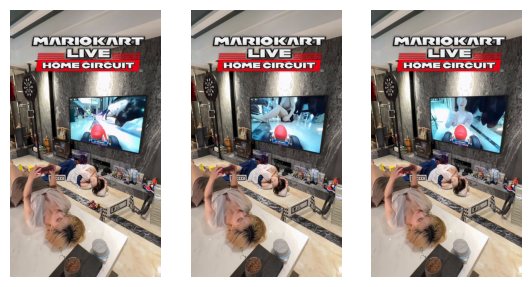

2679089229127088｜allie.liao｜label=0｜37.1s｜首尾 cos=0.934


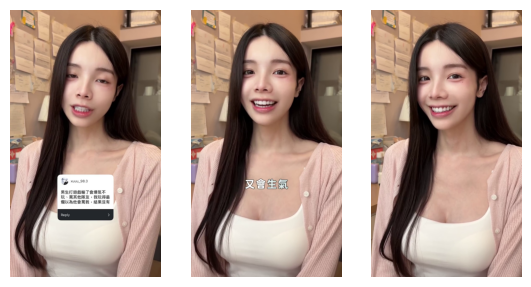

1365201935409883｜itsberrym｜label=0｜33.0s｜首尾 cos=0.895


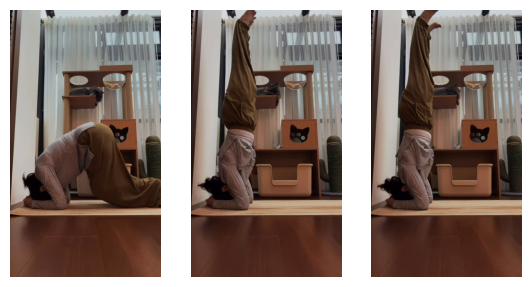

1315017367102406｜tiest0913｜label=0｜8.9s｜首尾 cos=0.939


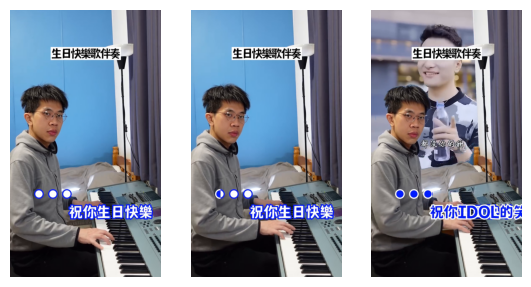

1422593562580438｜ruruspiano｜label=0｜59.5s｜首尾 cos=0.986


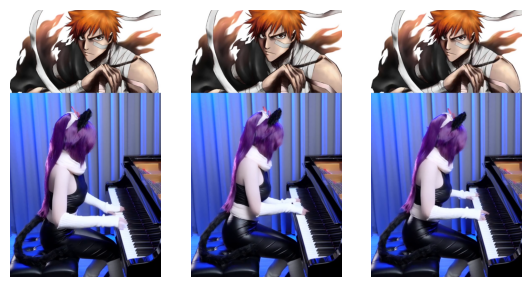

1467369001674985｜jasondchen｜label=0｜6.7s｜首尾 cos=0.978


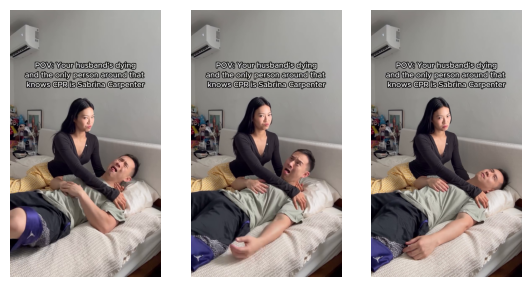

1658048125565962｜davio_magic｜label=0｜4.0s｜首尾 cos=0.966


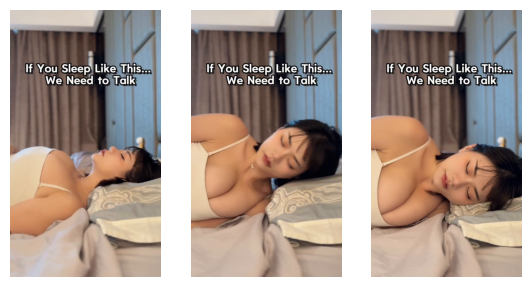

1244430991130655｜aries_8248｜label=0｜80.7s｜首尾 cos=0.916


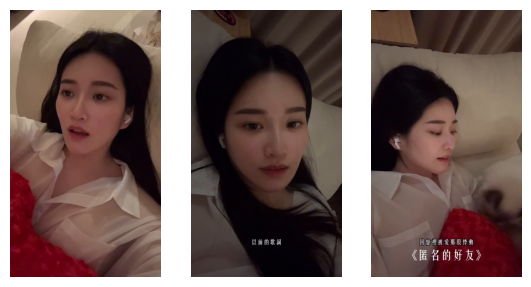

1428094689110954｜tiest0913｜label=0｜39.4s｜首尾 cos=0.937


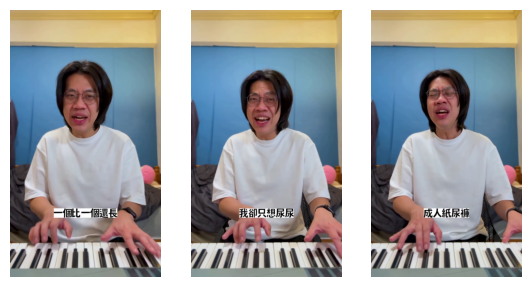

1449114766806030｜0_shufen｜label=0｜24.1s｜首尾 cos=0.974


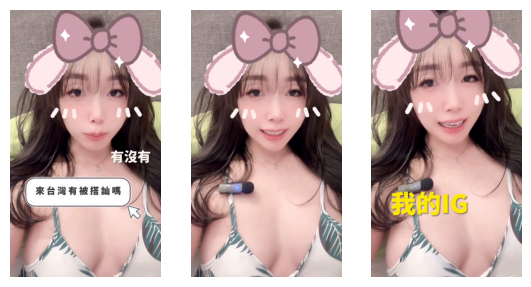

In [14]:
st = posts.loc[low_motion.numpy(), ["media_id", "username", "label", "duration", "video_path"]].copy()
rows = []
for m in st["media_id"]:
    fe = torch.load(CACHE_DIR / f"{m}.pt", weights_only=False)["frame_emb"].float()
    rows.append({"adj_cos": (fe[1:] * fe[:-1]).sum(-1).mean().item(),   # 相鄰影格平均相似度
                 "first_last_cos": (fe[0] * fe[-1]).sum().item(),        # 開頭 vs 結尾
                 "n_frames": len(fe)})
st = st.join(pd.DataFrame(rows, index=st.index))
print(st.drop(columns="video_path").round(3).to_string())
print("label 分布：", st["label"].value_counts().to_dict(), "｜全體業配比例 ≈ 0.455")

def peek(path, fracs=(0.1, 0.5, 0.9)):
    """只為了看圖：跳到影片 10% / 50% / 90% 的位置各取一格"""
    cap = cv2.VideoCapture(str(path))
    n, out = cap.get(cv2.CAP_PROP_FRAME_COUNT), []
    for f in fracs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(n * f))
        ok_, img = cap.read()
        if ok_:
            out.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    cap.release()
    return out

for r in st.itertuples():
    print(f"{r.media_id}｜{r.username}｜label={r.label}｜{r.duration:.1f}s｜首尾 cos={r.first_last_cos:.3f}")
    imgs = peek(r.video_path)
    fig, ax = plt.subplots(1, len(imgs), figsize=(2.2 * len(imgs), 4))
    for a, im in zip(np.atleast_1d(ax), imgs):
        a.imshow(im)
        a.axis("off")
    plt.show()

**上方檢查檢視結果（pilot，10 支）**
- 全部是固定鏡位的真實內容（彈鋼琴、講話、瑜珈、睡覺翻身等），沒有單張圖片做成的影片；首尾 cosine 0.895–0.986，畫面有變化但緩慢 → 標記由 static 改名為 low_motion
- 處理方式：照常保留，不視為缺模態
- 觀察：10 支中只有 1 支是業配（全體 45.5%）。推測業配影片多經剪輯（產品特寫、多鏡頭），很少一鏡到底，與「鏡頭數越多、業配比例越高」的發現一致。但這是事後觀察，且有兩位網紅各占 2 支、彼此不獨立，不做統計推論
- 唯一的業配影片（1591642668921614）業配訊號主要來自畫面上的大標題（遊戲名稱）→ 呼應 11.7：畫面文字含有合法的業配線索，遮蔽時只能遮揭露用語，不能遮掉所有文字

# 9. 快速檢查：影片向量有沒有業配訊號
用 logistic regression 做 linear probe，5-fold 交叉驗證。把每支影片的 768 維 embedding 當成輸入，讓 Logistic Regression 學習哪些數值組合與業配標籤有關。

**為什麼要按網紅分組（StratifiedGroupKFold）？**
同一位網紅的影片風格很像。如果同一位網紅的影片同時出現在訓練和測試裡，模型可能只是認出「這是常接業配的某某某」，分數會被高估。分組後，測試的網紅一定是模型沒看過的。

隨機基準 AP = 業配比例 = 136 / 299 ≈ 0.455

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import average_precision_score

ok = video_ok.numpy()
yv, g = posts["label"].values[ok], posts["person_id"].values[ok]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print("隨機基準 AP (業配數/全部)≈", yv.mean().round(3))
for p in POOLS:
    prob = cross_val_predict(LogisticRegression(max_iter=2000), X_V[p][ok].numpy(), yv,
                             cv=cv, groups=g, method="predict_proba")[:, 1]
    print(f"{p:10s} AP = {average_precision_score(yv, prob):.3f}")

隨機基準 AP (業配數/全部)≈ 0.455
max_k      AP = 0.771
mean_shot  AP = 0.680
mean_frame AP = 0.668
max        AP = 0.770


**=======================結果說明==========================**

影片向量具有能被簡單線性分類器利用的業配預測訊號，而且 Max 類型的 pooling 在這次實驗中較好。

# 10. 穩健性檢查：pooling 方法怎麼選出來的
每個設定用 10 個隨機種子重複，報告 AP 的平均 ± 標準差。

**第一、二輪：`max` 最好，但跟長度高度相關**
- `max` 0.785，遠高於 `mean_shot` 0.651、`mean_frame` 0.659
- 但只用影片長度就有 0.649；業配中位數 59.9 秒、非業配 37.1 秒
- `max` 向量的整體高度和 log(長度) 相關 0.686：格數越多，最大值必然越大
- 扣除長度效應後，`max` 掉到 0.553
→ 懷疑 `max` 只是在間接記錄影片長度

**第三輪：明確給出長度後，`max` 仍然領先**
- 長度 + mean_shot 0.657、長度 + max 0.783
→ `max` 有「線性長度」以外的資訊，可能是 (a) 非線性的長度效應，或 (b) 真的有關鍵畫面

**第四輪：分開兩種解釋**
- 每支都固定抽 32 格 → 格數造成的效應消失；長度改用 spline → 任何形狀都學得到
- 非線性長度單獨只有 0.625 → 排除 (a)
- `max_32` − `mean_32` = +0.086 ± 0.025，10 次全勝 → 支持 (b)
- 給了非線性長度後，`max_32` 仍比 `mean_32` 多 0.075，10 次全勝

**決定**：預設用 `max_k`（K = 32）。保留 SPoD「任何一張畫面出現產品就算」的 max-pool 邏輯，又不受影片長度影響。

**影片對文字有沒有幫助？**
- 跟「text + 長度」相比，加上 `max_32` 多 0.043、加上 `mean_32` 多 0.036，都是 10 次全勝 → 值得整合
- 有文字時，max 和 mean 的差距縮小（0.849 對 0.841），推測關鍵畫面的資訊和 caption 有部分重疊
- 長度單獨當 feature 只多約 0.006 → 不另設 aspect，之後當作 graph 的 post node feature

**限制**
- linear probe 不等於最終的 SPoD 模型
- 10 次重複用的是同一批資料，「10 次全勝」不是正式的顯著性檢定
- K = 32 是暫定值，正式實驗比較 16 / 32 / 64
- 業配和長度的關係要在 full 資料上再確認一次

## 10.1 重複交叉驗證，並納入影片長度與文字作對照
每個 seed 都換一種切法、重跑 10 次，看平均和標準差。另外加入幾組對照：只用影片長度、把長度效應從 max 扣掉、只用文字，以及文字加影片。

此交叉驗證的目的是在檢查當分類器面對訓練時沒看過的網紅時，使用這種特徵，還能不能維持好的排序表現？

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 影片長度與鏡頭數（從快取讀）
dur = np.array([torch.load(CACHE_DIR / f"{m}.pt", weights_only=False)["info"]["duration"]
                for m in posts["media_id"]])
ok  = video_ok.numpy()
yv, g = posts["label"].values[ok], posts["username"].values[ok]
log_dur = np.log(dur[ok])[:, None]

# Text embedding（與主 notebook 同一份）
t = torch.load(FEAT_DIR / "text" / "pilot_ckiplab_bert-base-chinese_masked.pt", weights_only=False)
tpos = {m: i for i, m in enumerate(t["media_id"])}
X_T = t["X_T"][[tpos[m] for m in posts["media_id"]]].numpy()[ok]

# 把 max 向量中可由「影片長度」線性解釋的部分扣掉（不使用 label，不會洩漏）
def residualize(X, z):
    Z = np.c_[np.ones(len(z)), z]
    return X - Z @ np.linalg.lstsq(Z, X, rcond=None)[0]

V = {p: X_V[p][ok].numpy() for p in POOLS}
candidates = {
    "長度 only":          np.c_[log_dur, np.log(n_shots[ok])[:, None]],
    "mean_shot":          V["mean_shot"],
    "mean_frame":         V["mean_frame"],
    "max":                V["max"],
    "max（扣除長度效應）": residualize(V["max"], log_dur),
    "text":               X_T,
    "text + mean_shot":   np.c_[X_T, V["mean_shot"]],
    "text + max":         np.c_[X_T, V["max"]],
}

def grouped_ap(X, seeds=range(10)):
    aps = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
        prob = cross_val_predict(clf, X, yv, cv=cv, groups=g, method="predict_proba")[:, 1]
        aps.append(average_precision_score(yv, prob))
    return np.mean(aps), np.std(aps)

print(f"隨機基準 AP ≈ {yv.mean():.3f}　｜　網紅數：{len(np.unique(g))}")
res = pd.DataFrame({k: grouped_ap(X) for k, X in candidates.items()}, index=["AP_mean", "AP_sd"]).T
print(res.round(3))

隨機基準 AP ≈ 0.455　｜　網紅數：99
                  AP_mean  AP_sd
長度 only             0.649  0.015
mean_shot           0.651  0.018
mean_frame          0.659  0.021
max                 0.785  0.017
max（扣除長度效應）         0.553  0.016
text                0.800  0.015
text + mean_shot    0.833  0.014
text + max          0.857  0.011


**=====================結果說明=========================**

在目前 Pilot 資料、固定的 SigLIP 2 特徵及 Logistic Regression 分類器下，Max pooling 的影片單模態排序表現優於 Mean pooling；當結合文字特徵後，Max pooling 的組合也得到較高 AP，而且文字與影片結合的表現高於單獨使用兩者

## 10.2 max與影片長度的關聯

In [17]:
mx_level = V["max"].mean(1)          # max 向量的整體高度
print("max 向量平均值 vs log(長度) 相關：", np.corrcoef(mx_level, log_dur[:, 0])[0, 1].round(3))
print("業配 / 非業配的影片長度中位數（秒）：",
      np.median(dur[ok][yv == 1]).round(1), "/", np.median(dur[ok][yv == 0]).round(1))

max 向量平均值 vs log(長度) 相關： 0.686
業配 / 非業配的影片長度中位數（秒）： 59.9 / 37.1


## 10.3 鏡頭數異常的影片

In [18]:
chk = posts.loc[ok, ["username", "stem", "label"]].assign(
    n_shots=n_shots[ok], duration=dur[ok].round(1))
chk["shots_per_sec"] = (chk["n_shots"] / chk["duration"]).round(2)
print(chk.sort_values("shots_per_sec", ascending=False).head(8).to_string())

           username                                            stem  label  n_shots  duration  shots_per_sec
204        japanuts        japanuts-20251228201320-2331979960639984      1       45      37.8           1.19
243        japanuts       japanuts-20251114225239-25897867413199158      1       16      15.7           1.02
123       hooleefun       hooleefun-20250727011908-1788470765402591      1       28      31.5           0.89
287          1105ya          1105ya-20250909075605-1937957040180651      0       10      11.4           0.88
275          khshu_           khshu_-20250610213234-930772389898260      1       45      53.6           0.84
0         ala780705       ala780705-20251214122010-2615877615465778      0       29      35.9           0.81
164       zoebitalk       zoebitalk-20250630230332-1492024018951094      0       11      13.8           0.80
70   ladyflavor_cui  ladyflavor_cui-20250726210517-1410621970514561      0       46      58.0           0.79


## 10.4 扣除長度後，影片內容的淨貢獻

In [19]:
L = candidates["長度 only"]
more = {
    "mean_shot（扣除長度效應）": residualize(V["mean_shot"], log_dur),   # 與 max 的同條件對照
    "長度 + mean_shot":          np.c_[L, V["mean_shot"]],
    "長度 + max":                np.c_[L, V["max"]],
    "text + 長度":               np.c_[X_T, L],
    "text + 長度 + mean_shot":   np.c_[X_T, L, V["mean_shot"]],
    "text + 長度 + max":         np.c_[X_T, L, V["max"]],
}
res2 = pd.DataFrame({k: grouped_ap(X) for k, X in more.items()}, index=["AP_mean", "AP_sd"]).T
print(res2.round(3))

                       AP_mean  AP_sd
mean_shot（扣除長度效應）        0.504  0.014
長度 + mean_shot           0.657  0.017
長度 + max                 0.783  0.017
text + 長度                0.808  0.015
text + 長度 + mean_shot    0.833  0.014
text + 長度 + max          0.856  0.011


## 10.5 固定格數pooling與非線性長度

**線性關係**： 影片每增加一定的長度，業配傾向就按照固定幅度改變。例如從 20 秒增加到 40 秒，和從 80 秒增加到 100 秒，都增加相同幅度的預測分數。

**非線性關係**： 影片長度與業配之間可能存在轉折。例如 10–30 秒業配傾向快速上升，30–60 秒變化很小，超過 90 秒又出現不同的趨勢。

**=======================程式碼解釋=========================**

**log(秒數)**： 先把影片長度轉成對數。例如 10、30、60、120 秒，分別約變成 2.30、3.40、4.09、4.79。較長影片之間的差距會被壓縮。

**SplineTransformer**： 把對數長度轉成多個數值特徵，讓 Logistic Regression 可以學出彎曲、有轉折的長度關係，而不必只學一條直線。這裡的 n_knots=6 是設定六個樣條節點，degree=3 表示三次樣條。

**log(鏡頭數)**： 再提供影片切換鏡頭的數量，例如 5 個鏡頭與 30 個鏡頭。這讓模型除了知道影片有多長，也知道它大致有多少剪接片段。

In [20]:
from sklearn.preprocessing import SplineTransformer

# 非線性長度：log(秒數) 的 spline 展開 + log(鏡頭數)（不使用 label，不會洩漏）
L_nl = np.c_[SplineTransformer(n_knots=6, degree=3).fit_transform(log_dur),
             np.log(n_shots[ok])[:, None]]

# 固定格數 pooling：每支影片均勻取 K 格，消除「格數越多、最大值越高」的效應
K = 32
def fixed_k_pool(media_id, k=K):
    fe = torch.load(CACHE_DIR / f"{media_id}.pt", weights_only=False)["frame_emb"].float()
    sub = fe[np.linspace(0, len(fe) - 1, k).round().astype(int)]
    return sub.mean(0).numpy(), sub.max(0).values.numpy()

_p = [fixed_k_pool(m) for m in tqdm(posts["media_id"][ok], desc=f"fixed-{K}")]
mean_k = np.stack([a for a, _ in _p])
max_k  = np.stack([b for _, b in _p])
print("max_K 平均值 vs log(長度) 相關：", np.corrcoef(max_k.mean(1), log_dur[:, 0])[0, 1].round(3))

def ap_runs(X, seeds=range(10)):
    out = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
        prob = cross_val_predict(clf, X, yv, cv=cv, groups=g, method="predict_proba")[:, 1]
        out.append(average_precision_score(yv, prob))
    return np.array(out)

runs = {
    "長度(非線性)":           L_nl,
    "max（原本）":            V["max"],
    f"mean_{K}":              mean_k,
    f"max_{K}":               max_k,
    "長度(非線性) + max":      np.c_[L_nl, V["max"]],
    f"長度(非線性) + mean_{K}": np.c_[L_nl, mean_k],
    f"長度(非線性) + max_{K}":  np.c_[L_nl, max_k],
    "text + 長度(非線性)":     np.c_[X_T, L_nl],
    f"text + 長度(非線性) + mean_{K}": np.c_[X_T, L_nl, mean_k],
    f"text + 長度(非線性) + max_{K}":  np.c_[X_T, L_nl, max_k],
    "text + 長度(非線性) + max":       np.c_[X_T, L_nl, V["max"]],
}
R = {k: ap_runs(X) for k, X in tqdm(runs.items(), desc="CV")}
print(pd.DataFrame({k: [v.mean(), v.std()] for k, v in R.items()},
                   index=["AP_mean", "AP_sd"]).T.round(3))

# 成對比較：同樣 10 種切法下的差值
def paired(a, b):
    d = R[a] - R[b]
    return f"{a}  −  {b}:  Δ = {d.mean():+.3f} ± {d.std():.3f}｜10 次中贏 {int((d > 0).sum())} 次"

print()
for a, b in [(f"max_{K}", f"mean_{K}"),
             (f"長度(非線性) + max_{K}", "長度(非線性)"),
             (f"長度(非線性) + max_{K}", f"長度(非線性) + mean_{K}"),
             (f"text + 長度(非線性) + mean_{K}", "text + 長度(非線性)"),
             (f"text + 長度(非線性) + max_{K}", "text + 長度(非線性)")]:
    print(paired(a, b))

fixed-32:   0%|          | 0/299 [00:00<?, ?it/s]

max_K 平均值 vs log(長度) 相關： 0.504


CV:   0%|          | 0/11 [00:00<?, ?it/s]

                          AP_mean  AP_sd
長度(非線性)                     0.625  0.013
max（原本）                     0.785  0.017
mean_32                     0.655  0.021
max_32                      0.741  0.021
長度(非線性) + max               0.776  0.019
長度(非線性) + mean_32           0.659  0.027
長度(非線性) + max_32            0.734  0.020
text + 長度(非線性)              0.806  0.019
text + 長度(非線性) + mean_32    0.841  0.012
text + 長度(非線性) + max_32     0.849  0.011
text + 長度(非線性) + max        0.855  0.011

max_32  −  mean_32:  Δ = +0.086 ± 0.025｜10 次中贏 10 次
長度(非線性) + max_32  −  長度(非線性):  Δ = +0.109 ± 0.015｜10 次中贏 10 次
長度(非線性) + max_32  −  長度(非線性) + mean_32:  Δ = +0.075 ± 0.024｜10 次中贏 10 次
text + 長度(非線性) + mean_32  −  text + 長度(非線性):  Δ = +0.036 ± 0.015｜10 次中贏 10 次
text + 長度(非線性) + max_32  −  text + 長度(非線性):  Δ = +0.043 ± 0.015｜10 次中贏 10 次


**==========================結果解讀====================================**

第一，單純知道影片長度與鏡頭數，就已經能達到 0.625 AP。這告訴我們，**影片的結構資訊本身具有預測能力**。

第二，固定 32 格後，Max 的 AP 是 0.741，高於 Mean 的 0.655。這支持 **Max 在你的 Pilot 資料中，更能保留對分類有用的特徵**。

第三，文字加上非線性長度的 AP 是 0.806，加入 Max 32 後提高到 0.849，增加了 0.043。這是整個實驗特別重要的發現：**在已有文字與影片結構資訊的條件下，影片 embedding 仍然帶來額外預測能力**。

不過，這還不能完全證明模型真的辨認到了「產品展示」或「業配場景」。它可能使用其他視覺線索，例如拍攝方式、影像品質或畫面文字。要進一步知道原因，還需要做遮蔽實驗、錯誤案例分析或其他消融實驗。

## 10.6 依鏡頭取樣 (shot-aware sampling)

In [21]:
def shot_aware_idx(ts, shots, k=K):
    """每個鏡頭至少 1 格，剩下的名額依鏡頭長度分配；鏡頭數 ≥ K 時，均勻挑 K 個鏡頭各取 1 格"""
    shots = [(s, e) for s, e in shots if ((ts >= s) & (ts < e)).any()]
    if len(shots) >= k:
        pick = np.linspace(0, len(shots) - 1, k).round().astype(int)
        shots, alloc = [shots[i] for i in pick], np.ones(k, dtype=int)
    else:
        dur = np.array([e - s for s, e in shots])
        alloc = 1 + np.floor((k - len(shots)) * dur / dur.sum()).astype(int)
        alloc[np.argsort(-dur)[:k - alloc.sum()]] += 1      # 補足捨入誤差，總數剛好 K
    idx = []
    for (s, e), a in zip(shots, alloc):
        cand = np.flatnonzero((ts >= s) & (ts < e))
        idx += cand[np.linspace(0, len(cand) - 1, a).round().astype(int)].tolist()
    return np.array(idx)

def shot_aware_pool(media_id):
    c = torch.load(CACHE_DIR / f"{media_id}.pt", weights_only=False)
    fe = c["frame_emb"].float()
    return fe[shot_aware_idx(np.asarray(c["ts"]), c["shots_sec"])].max(0).values.numpy()

max_sa = np.stack([shot_aware_pool(m) for m in tqdm(posts["media_id"][ok], desc="shot-aware")])
R[f"max_{K}_shot"] = ap_runs(max_sa)
R[f"text + 長度(非線性) + max_{K}_shot"] = ap_runs(np.c_[X_T, L_nl, max_sa])

print(f"max_{K}_shot：{R[f'max_{K}_shot'].mean():.3f} ± {R[f'max_{K}_shot'].std():.3f}")
print(paired(f"max_{K}_shot", f"max_{K}"))
print(paired(f"text + 長度(非線性) + max_{K}_shot", f"text + 長度(非線性) + max_{K}"))

shot-aware:   0%|          | 0/299 [00:00<?, ?it/s]

max_32_shot：0.758 ± 0.014
max_32_shot  −  max_32:  Δ = +0.017 ± 0.010｜10 次中贏 10 次
text + 長度(非線性) + max_32_shot  −  text + 長度(非線性) + max_32:  Δ = -0.005 ± 0.004｜10 次中贏 1 次


# 11. 畫面揭露字樣檢查與遮蔽（OCR）
**為什麼要做**：SPoD §4.1.2 會刪除揭露用的關鍵字，避免模型靠「#業配」這類字判斷。SPoD 的 Inception-V3 讀不懂畫面文字，但 SigLIP 2 讀得懂，所以影片畫面是我們新增的洩漏管道。
**流程**：關鍵詞篩選候選（11.2）→ 人工驗證（11.4–11.5）→ 只遮蔽確認為揭露者（11.6）
**Pilot 結果**
- 下載工具：Instaloader 235、MetaTool 64（MetaTool 是否為原始檔下載待確認）
- OCR 候選 4 支（業配 3、非業配 1），人工確認全為誤判 → 遮蔽 0 支，max_k_masked = max_k
- 遮蔽 4 支候選前後的 AP 無差異（Δ ≈ 0）
- Ablation（11.7）：69.5% 的影格有文字；遮蔽所有文字後，只看影片 AP 降 0.027，加上文字後只降 0.008（皆 10 次中 9 次）→ 影片的訊號主要來自畫面本身
**限制**：只檢查 max_k 用到的 32 格；EasyOCR 對花體字、動態字卡的辨識率未知，4 支是下限

## 11.0 揭露詞辭庫 (與Model的caption遮蔽相同)

In [22]:
# 與主 notebook「### 文字清理與業配詞刪除」完全相同；之後改詞庫時兩邊要同步

import re, unicodedata

def drop_redundant(terms):
    """去掉重複詞，以及「已被較短詞涵蓋」的長詞（例如有「買」就不用「購買」）"""
    keep = []
    for t in sorted(set(terms), key=len):
        if not any(k in t for k in keep):
            keep.append(t)
    removed = sorted(set(terms) - set(keep))
    if removed:
        print("已自動移除（重複或被涵蓋）：", removed)
    return keep

# ── 中文（繁體）──
ZH_STRICT = [
    # 揭露與合作
    "業配", "工商", "廣告", "贊助", "置入", "合作", "公關", "品牌", "廠商", "乾爹",
    "邀請", "受邀", "邀約", "邀稿", "互惠", "付費", "PR品", "PR文",
    # 試用、贈品
    "試用", "贈品", "贈送",
    # 促銷、導購
    "優惠", "折扣", "折價", "特價", "免運", "推薦碼", "專屬碼", "序號", "抽獎",
    "團購", "開團", "跟團", "揪團", "下單", "結帳", "購物車", "導購", "好物",
    # 反向聲明（「沒有業配」同樣會洩漏答案）
    "自費", "自掏腰包",
]
# ── 中文（簡體）──
ZH_SIMPLIFIED = [
    "业配", "广告", "赞助", "公关", "厂商", "邀请", "邀约", "付费",
    "试用", "赠品", "赠送", "优惠", "折价", "特价", "免运", "推荐码", "专属码",
    "抽奖", "团购", "开团", "跟团", "下单", "结账", "购物车", "导购", "自费",
]
# ── 日文 ──
JA_TERMS = [
    "広告", "プロモーション", "タイアップ", "スポンサー", "協賛", "宣伝", "ステマ",
    "案件", "商品提供", "提供品", "ギフティング", "招待", "依頼",
    "アフィリエイト", "クーポン", "割引", "購入", "自腹",
]
# ── 韓文 ──
KO_TERMS = [
    "광고", "협찬", "제공받", "원고료", "체험단", "서포터즈", "앰배서더",
    "공구", "공동구매", "할인", "쿠폰", "구매", "증정", "선물받",
    "파트너스", "수수료", "내돈내산",
]

# ── 英文 hashtag（完整比對：#ad 不會誤刪 #adidas）──
EN_HASHTAG = [
    "ad", "ads", "advert", "advertisement", "advertising", "spon", "sp",
    "sponsored", "sponsor", "sponsorship", "notsponsored", "nonsponsored", "notanad",
    "paidpartnership", "paidpost", "partner", "partnership", "brandpartner",
    "ambassador", "brandambassador", "collab", "collaboration",
    "gifted", "giftedby", "pr", "prsample", "prpackage", "promo", "promotion",
    "promocode", "discountcode", "affiliate", "affiliatelink", "commissionsearned",
    "giveaway", "linkinbio", "shopnow",
]
# ── 英文字詞與片語（文中任何位置，不分大小寫）──
EN_PHRASE = [
    r"ads?", r"advert\w*", r"sponsor\w*", r"promo\w*", r"affiliate\w*",
    r"paid\s+partnership", r"in\s+partnership\s+with", r"partnered\s+with",
    r"in\s+collaboration\s+with", r"collab\w*", r"brand\s+(?:deal|partner|ambassador)\w*",
    r"gifted(?:\s+by)?", r"pr\s+(?:sample|package|package)s?",
    r"discount\s+code", r"coupon\w*", r"use\s+(?:my\s+)?code", r"code\s*:",
    r"link\s+in\s+(?:my\s+)?bio", r"swipe\s+up", r"shop\s+now", r"buy\s+now",
    r"giveaway\w*", r"free\s+shipping", r"commission\w*",
]

OTHER_LANG = JA_TERMS + KO_TERMS
CJK_TERMS  = drop_redundant(ZH_STRICT + ZH_SIMPLIFIED + OTHER_LANG)

# Tier 2：模糊詞 → 預設不刪，ablation 時可加入（「合作」已移到必刪清單）
ZH_OPTIONAL = ["感謝", "連結", "開箱", "推薦", "官網", "私訊", "限定"]

def build_patterns(cjk_terms):
    cjk = "|".join(map(re.escape, sorted(cjk_terms, key=len, reverse=True)))
    tags = "|".join(sorted(EN_HASHTAG, key=len, reverse=True))
    return [
        re.compile(r"[【\[(〔]\s*(?:PR|AD|広告|廣告|广告|광고|業配|Sponsored)\s*[】\])〕]",
                   re.IGNORECASE),                                      # 【PR】、[AD]、(廣告)
        re.compile(rf"#[^\s#]*(?:{cjk})[^\s#]*"),                       # 含 CJK 揭露詞的整個 hashtag
        re.compile(rf"#(?:{tags})\b", re.IGNORECASE),                   # 英文 hashtag
        re.compile(rf"\b(?:{'|'.join(EN_PHRASE)})\b", re.IGNORECASE),   # 英文字詞與片語
        re.compile(rf"(?:{cjk})"),                                      # 剩下的 CJK 裸字
    ]

PATTERNS = build_patterns(CJK_TERMS)
print(f"CJK 詞彙 {len(CJK_TERMS)} 個，英文 hashtag {len(EN_HASHTAG)} 個，英文字詞 {len(EN_PHRASE)} 組")

def normalize(text):
    text = unicodedata.normalize("NFKC", text)        # 全形 → 半形
    text = re.sub(r"https?://\S+", " ", text)         # 刪網址
    return re.sub(r"\s+", " ", text).strip()

已自動移除（重複或被涵蓋）： ['공동구매']
CJK 詞彙 101 個，英文 hashtag 37 個，英文字詞 24 組


## 11.1 確認下載工具(有無螢幕錄影)

In [31]:
META_DIR = DATA_ROOT / "Metadata_by_Influencer"
tools = pd.concat([pd.read_csv(META_DIR / f"{u}-FullVideoInfo.csv", dtype={"media_id": str},
                               usecols=["media_id", "DownloadTool"])
                   for u in posts["username"].unique()])
tools["media_id"] = tools["media_id"].str.strip()
print(posts.merge(tools.drop_duplicates("media_id"), on="media_id", how="left")["DownloadTool"]
          .value_counts(dropna=False))

DownloadTool
Instaloader    235
MetaTool        64
Name: count, dtype: int64


## 11.2 OCR檢查 (只看max_k用到的32格)

In [23]:
# pip install easyocr
import easyocr

OCR_CONF  = 0.4                 # 低於這個信心分數的辨識結果不採用 ← 自訂
OCR_LANGS = [["ch_tra", "en"]]  # EasyOCR 每個 reader 只能有一種中日韓文字；需要時加入 ["ch_sim","en"]、["ja","en"]、["ko","en"]
MASK_MODE = "all_hits"          # "all_hits"：命中就遮（與 caption 相同規則）；"verified"：人工確認後才遮
readers = [easyocr.Reader(langs, gpu=torch.cuda.is_available()) for langs in OCR_LANGS]

def grab_frames(path, frame_ids):
    """依序讀取，只取指定的影格編號（與 sample_frames 同一套讀法，確保是同一格）"""
    want, out, i = set(int(f) for f in frame_ids), {}, 0
    cap, last = cv2.VideoCapture(str(path)), max(frame_ids)
    while i <= last and cap.grab():
        if i in want:
            ok_, img = cap.retrieve()
            if ok_:
                out[i] = img
        i += 1
    cap.release()
    return out

def ocr_raw(row):
    """max_k 用到的 32 格裡，所有偵測到的文字（含內容、位置、信心分數）"""
    c = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)
    ts, fps = np.asarray(c["ts"]), c["info"]["fps"]
    sel  = np.linspace(0, len(ts) - 1, FIXED_K).round().astype(int)   # = max_k 用到的格
    fids = np.round(ts[sel] * fps).astype(int)                         # 換回原始影格編號
    frames, out = grab_frames(row.video_path, fids), []
    for j, fid in zip(sel, fids):
        if fid not in frames:
            continue
        for rd in readers:
            for box, text, conf in rd.readtext(frames[fid]):           # 原解析度辨識，較準
                out.append({"frame_idx": int(j), "fid": int(fid), "box": box,
                            "text": text, "conf": float(conf)})
    return out

# ── OCR 只做一次：所有文字存成快取；之後改詞庫只需重新比對 ──
LANG_TAG    = "+".join("-".join(l) for l in OCR_LANGS)
OCR_RAW_PKL = CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_ocr_raw_{LANG_TAG}.pkl"
ocr_raw_all = pd.read_pickle(OCR_RAW_PKL) if OCR_RAW_PKL.exists() else {}
todo = [r for r in posts[ok].itertuples() if r.media_id not in ocr_raw_all]
for n, row in enumerate(tqdm(todo, desc="OCR"), 1):
    ocr_raw_all[row.media_id] = ocr_raw(row)
    if n % 50 == 0:
        pd.to_pickle(ocr_raw_all, OCR_RAW_PKL)          # 每 50 支存一次，中斷可續跑
if todo:
    pd.to_pickle(ocr_raw_all, OCR_RAW_PKL)
print(f"OCR 快取：{OCR_RAW_PKL.name}｜新跑 {len(todo)} 支，沿用 {len(ocr_raw_all) - len(todo)} 支")

# ── 用 11.0 的詞庫比對（幾秒鐘，改詞庫後重跑這段即可）──
def match_terms(text):
    t = normalize(text)
    return [m for p in PATTERNS for m in p.findall(t)]

ocr_hits = {}
for m, dets in ocr_raw_all.items():
    hs = []
    for d in dets:
        terms = match_terms(d["text"]) if d["conf"] >= OCR_CONF else []
        if terms:
            hs.append({**d, "terms": terms})
    ocr_hits[m] = hs

posts["ocr_terms"] = posts["media_id"].map(
    lambda m: sorted({t for h in ocr_hits.get(m, []) for t in h["terms"]}))

# 洩漏檢查：與 caption 那邊的表格格式相同，方便對照
print(posts.assign(hit=posts["ocr_terms"].str.len() > 0)
           .groupby("label")["hit"].agg(["mean", "sum", "count"]))
# 哪些詞命中最多（若單一詞在兩種 label 都大量出現，代表它多半是一般用語）
print(pd.Series([t for hs in ocr_hits.values() for h in hs for t in h["terms"]])
        .value_counts().head(20).to_string())

OCR:   0%|          | 0/299 [00:00<?, ?it/s]

OCR 快取：pilot_siglip2-base-patch16-naflex_p256_fps4_ocr_raw_ch_tra-en.pkl｜新跑 299 支，沿用 0 支
           mean  sum  count
label                      
0      0.030675    5    163
1      0.220588   30    136
優惠             15
品牌             11
免運              6
下單              4
廠商              4
合作              4
試用              3
結帳              2
團購              2
受邀              2
邀請              2
付費              2
折扣              2
廣告              2
案件              1
promotional     1
開團              1
贈品              1
購物車             1
特價              1


## 11.3 遮蔽後重新編碼，比較遮蔽前後的AP

In [24]:
def to_pil(img):
    """與 sample_frames 相同的縮圖流程，確保沒被遮蔽的部分 embedding 不變"""
    h, w = img.shape[:2]
    s = RESIZE_LONG / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

def mask_boxes(img, boxes, pad=4):
    """用該區域的平均色塗滿整行字（對應 caption 刪除整個 hashtag 的做法）"""
    img = img.copy()
    for box in boxes:
        pts = np.array(box, dtype=int)
        x0, y0 = np.maximum(pts.min(0) - pad, 0)
        x1, y1 = pts.max(0) + pad
        roi = img[y0:y1, x0:x1]
        if roi.size:
            img[y0:y1, x0:x1] = roi.reshape(-1, 3).mean(0)
    return img

def masked_frame_emb(row, hits):
    fe = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float().clone()
    groups = {}
    for h in hits:
        groups.setdefault((h["frame_idx"], h["fid"]), []).append(h["box"])
    frames = grab_frames(row.video_path, [fid for _, fid in groups])
    keys = [k for k in groups if k[1] in frames]
    if keys:
        fe[[j for j, _ in keys]] = encode_frames([to_pil(mask_boxes(frames[fid], groups[(j, fid)]))
                                                  for j, fid in keys])
    return fe

X_mk = []
for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="mask"):
    hits = ocr_hits.get(row.media_id, [])
    fe = (masked_frame_emb(row, hits) if hits else
          torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
    X_mk.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
X_mk = np.stack(X_mk)

R[f"max_{K}_masked"] = ap_runs(X_mk)
R[f"text + 長度(非線性) + max_{K}_masked"] = ap_runs(np.c_[X_T, L_nl, X_mk])
print(paired(f"max_{K}", f"max_{K}_masked"))
print(paired(f"text + 長度(非線性) + max_{K}", f"text + 長度(非線性) + max_{K}_masked"))

mask:   0%|          | 0/299 [00:00<?, ?it/s]

max_32  −  max_32_masked:  Δ = +0.007 ± 0.002｜10 次中贏 10 次
text + 長度(非線性) + max_32  −  text + 長度(非線性) + max_32_masked:  Δ = +0.002 ± 0.001｜10 次中贏 10 次


## 11.4 檢視被偵測到揭露字樣的影片

命中影片： 35 支


,media_id,username,stem,label,ocr_terms
0,1462778065349363,shasha77.daily,shasha77.daily-20251113101117-1462778065349363,1,[案件]
1,5281224238768543,coindevanity,coindevanity-20250910095816-5281224238768543,1,[優惠]
2,1428009839061025,japanuts,japanuts-20250219072254-1428009839061025,1,[品牌]
3,1069892868626983,taiwan_bar,taiwan_bar-20250907000218-1069892868626983,1,[合作]
4,1235579011358619,shasha77.daily,shasha77.daily-20250917141425-1235579011358619,1,[受邀]
5,2319105475229025,taiwan_bar,taiwan_bar-20251208232108-2319105475229025,1,"[品牌, 邀請]"
6,902164885533364,shasha77.daily,shasha77.daily-20250216154937-902164885533364,1,"[合作, 品牌, 團購]"
7,1293976569284808,mypink0911,mypink0911-20251124091953-1293976569284808,0,"[優惠, 品牌]"
8,1413473406899447,yga0721,yga0721-20250828230651-1413473406899447,1,[下單]
9,1225284129314984,japanuts,japanuts-20250715145410-1225284129314984,1,[品牌]


media_id=1613048089709392｜label=0｜第 75.5 秒｜OCR：所以他打不同的品牌啦｜命中：['品牌']


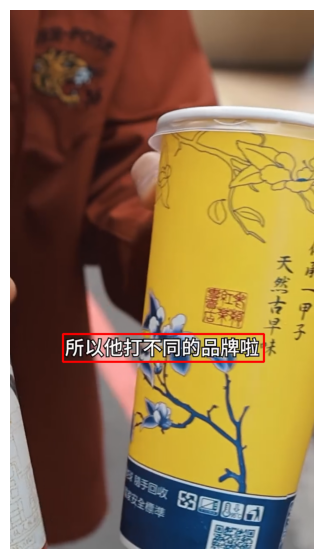

media_id=4059658970981895｜label=1｜第 41.7 秒｜OCR：樓下餐廳還有提供付費的｜命中：['付費']


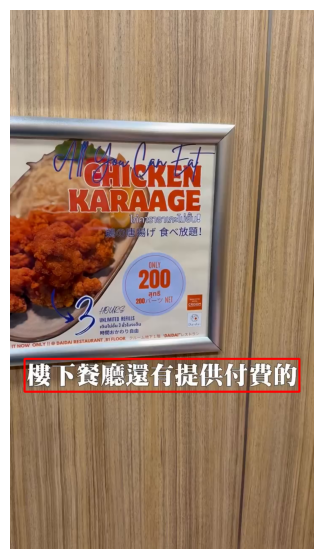

media_id=4059658970981895｜label=1｜第 43.5 秒｜OCR：樓下餐廳還有提供付費的｜命中：['付費']


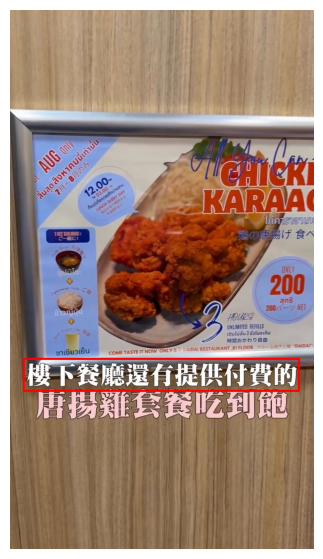

media_id=1407222434239556｜label=0｜第 9.5 秒｜OCR：幫我拿去櫃1結帳｜命中：['結帳']


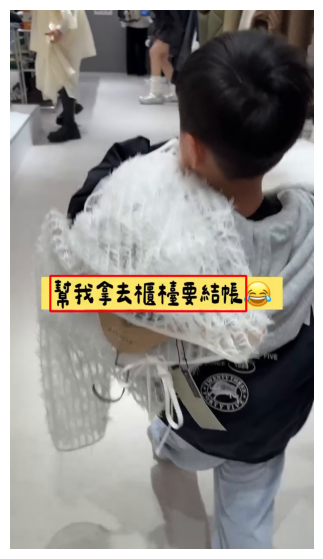

media_id=2121763511892034｜label=1｜第 17.0 秒｜OCR：第一次團購就獻給他們了!｜命中：['團購']


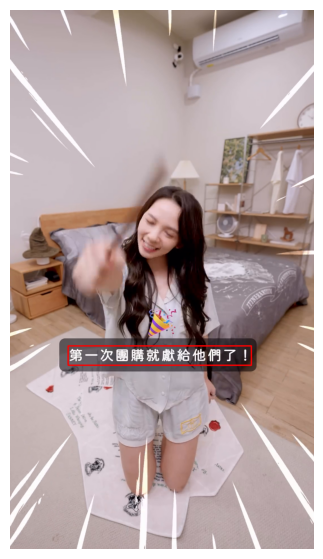

media_id=2121763511892034｜label=1｜第 73.7 秒｜OCR：以上就是我首次開團購的詳細介紹｜命中：['開團']


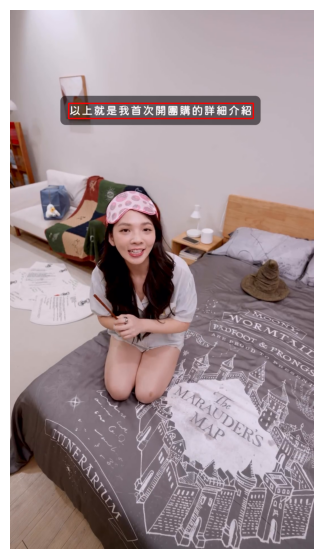

media_id=2121763511892034｜label=1｜第 82.3 秒｜OCR：前100組下單還可以拿到｜命中：['下單']


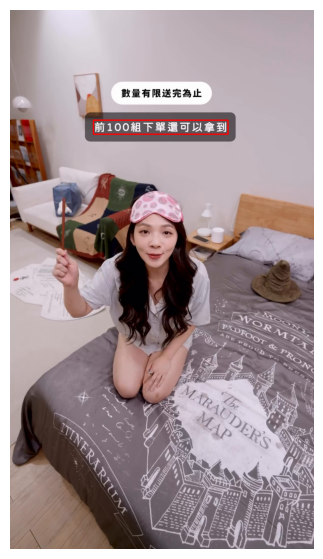

media_id=899583409141416｜label=1｜第 29.0 秒｜OCR：左下單一顆的那個｜命中：['下單']


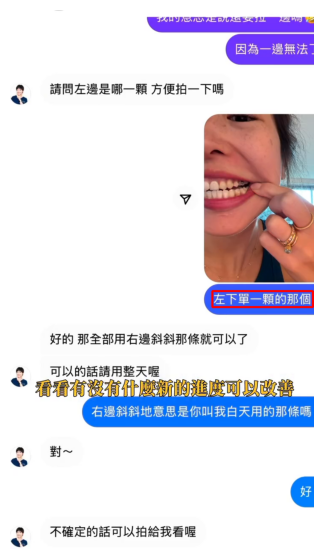

media_id=1977223306553885｜label=1｜第 58.0 秒｜OCR：廣告刊｜命中：['廣告']


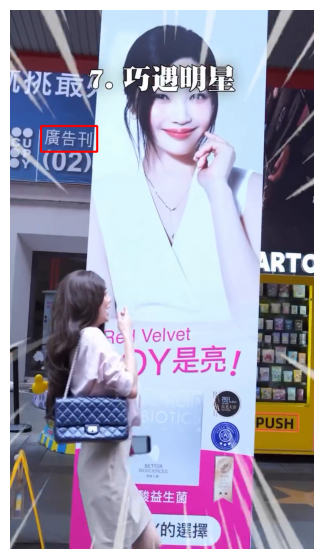

media_id=960256483534474｜label=1｜第 53.7 秒｜OCR：全系列單品優惠｜命中：['優惠']


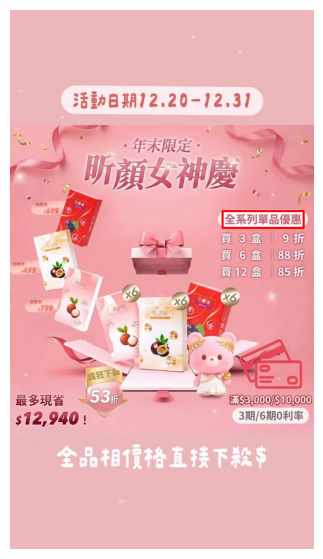

media_id=1772588043718668｜label=1｜第 47.7 秒｜OCR：閃購優惠倒數｜命中：['優惠']


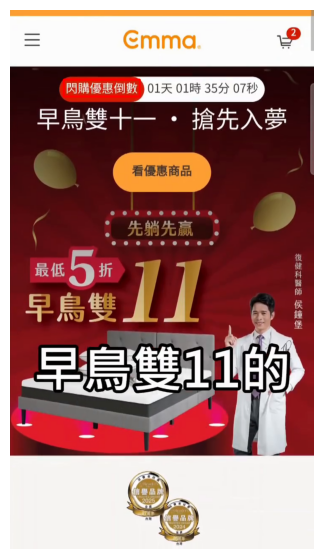

media_id=1772588043718668｜label=1｜第 47.7 秒｜OCR：看優惠商品｜命中：['優惠']


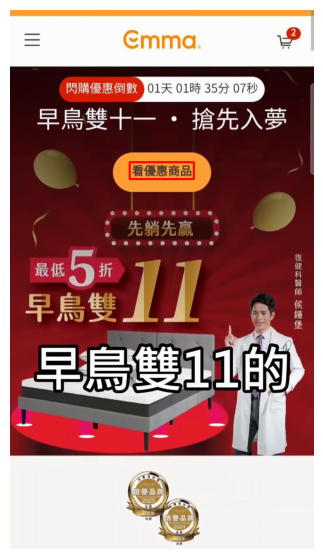

media_id=1772588043718668｜label=1｜第 47.7 秒｜OCR：品牌｜命中：['品牌']


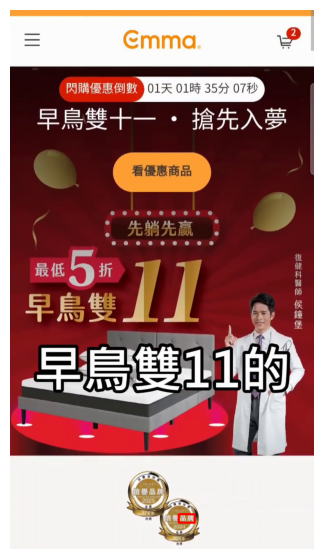

In [25]:
hit_df = (posts.loc[posts["ocr_terms"].str.len() > 0,
                    ["media_id", "username", "stem", "label", "ocr_terms", "video_path"]]
               .reset_index(drop=True))
pd.set_option("display.max_colwidth", None)
print("命中影片：", len(hit_df), "支")
display(hit_df.drop(columns="video_path"))

# 隨機抽幾支顯示，紅框 = OCR 找到的那行字（用於人工抽查）
N_SHOW = 8
show = hit_df.sample(min(N_SHOW, len(hit_df)), random_state=SEED) if len(hit_df) else hit_df
for row in show.itertuples():
    fps  = torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["info"]["fps"]
    hits = ocr_hits[row.media_id][:3]                       # 每支最多顯示 3 處
    frames = grab_frames(row.video_path, [h["fid"] for h in hits])
    for h in hits:
        print(f"media_id={row.media_id}｜label={row.label}｜第 {h['fid'] / fps:.1f} 秒｜OCR：{h['text']}｜命中：{h['terms']}")
        img = frames[h["fid"]].copy()
        cv2.polylines(img, [np.array(h["box"], dtype=np.int32)], True, (0, 0, 255), 3)
        plt.figure(figsize=(4, 7))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()

## 11.5 人工驗證紀錄

In [26]:
# 人工判讀：media_id → (是否為業配揭露或導購用語, 理由)；定義與 caption 刪除規則相同
# all_hits 模式下只需抽查（估計關鍵詞的誤判率）；verified 模式下必須判讀全部候選
REVIEW = {
    "2066126817504081": (False, "知識類影片，談商品廣告造成貼文倦怠"),
    "2436292660163202": (False, "主角敘述與廠商相關的經歷，非業配該廠商"),
    "1977223306553885": (False, "背景招牌上的「廣告」，路過入鏡"),
    "3471424433013354": (False, "「廠商」是他預設的受眾，不是在說自己幫某廠商業配"),
}
OCR_REVIEW = hit_df[["media_id", "username", "label", "ocr_terms"]].assign(
    is_disclosure=hit_df["media_id"].map(lambda m: REVIEW[m][0] if m in REVIEW else None),
    note=hit_df["media_id"].map(lambda m: REVIEW[m][1] if m in REVIEW else None),
)
reviewed = OCR_REVIEW["is_disclosure"].notna()
n_true = int(OCR_REVIEW.loc[reviewed, "is_disclosure"].astype(bool).sum())
print(f"候選 {len(OCR_REVIEW)} 支｜已人工判讀 {int(reviewed.sum())} 支｜其中確認為揭露或導購 {n_true} 支")

if MASK_MODE == "verified":
    assert reviewed.all(), "verified 模式需要判讀所有候選"
    verified = set(OCR_REVIEW.loc[OCR_REVIEW["is_disclosure"] == True, "media_id"])
else:
    verified = set(OCR_REVIEW["media_id"])            # 命中就遮，與 caption 規則相同

OCR_REVIEW.to_csv(CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_ocr_review.csv", index=False)
print(f"MASK_MODE = {MASK_MODE}｜將遮蔽 {len(verified)} 支影片")

候選 35 支｜已人工判讀 4 支｜其中確認為揭露或導購 0 支
MASK_MODE = all_hits｜將遮蔽 35 支影片


## 11.6 寫回彙整檔：只遮蔽驗證過的影片

In [27]:
# 只遮蔽人工確認為揭露的影片；pilot 的 verified 是空集合，結果會等於 max_k
X_ver = []
for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="verified mask"):
    hits = ocr_hits.get(row.media_id, []) if row.media_id in verified else []
    fe = (masked_frame_emb(row, hits) if hits else
          torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
    X_ver.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
X_ver = np.stack(X_ver)

saved = torch.load(OUT_PT, weights_only=False)
assert saved["media_id"] == posts["media_id"].tolist()
full = torch.zeros(len(posts), X_ver.shape[1])
full[torch.from_numpy(ok)] = torch.from_numpy(X_ver).float()
saved["X_V"]["max_k_masked"] = full
saved["config"]["ocr"] = {"engine": f"easyocr {LANG_TAG}", "conf": OCR_CONF,
                          "frames": f"max_k 的 {FIXED_K} 格", "terms": "與 caption 相同（11.0）",
                          "mask_mode": MASK_MODE, "n_candidates": len(OCR_REVIEW),
                          "n_reviewed": int(reviewed.sum()), "n_masked": len(verified)}
torch.save(saved, OUT_PT)
print("max_k_masked 已更新（遮蔽", len(verified), "支）")

verified mask:   0%|          | 0/299 [00:00<?, ?it/s]

max_k_masked 已更新（遮蔽 35 支）


## 11.7 Ablation：遮蔽畫面上所有文字（選用）
把 max_k 那 32 格裡**所有** OCR 偵測到的文字都用平均色塗掉，再重新編碼。
目的：區分影片的業配訊號來自「畫面上的文字」（字幕、產品名、價格），還是「畫面本身」（產品、場景、拍攝方式）。
⚠️ 這只是 ablation，不當預設：產品名、折扣碼等是合法的業配線索，正式模型應該保留。
⚠️ 有文字的影格都要重新編碼，可能會跑一陣子。結果存在獨立的 `*_notext.pt`，跑過一次之後會直接讀檔；換成 full 資料集或改了上游設定（模型、取樣、OCR）時，設 `RECOMPUTE = True` 重算。

In [ ]:
def ocr_all_text(row):
    """所有文字框，直接取自 11.2 的 OCR 快取（不重跑 OCR）"""
    return [d for d in ocr_raw_all[row.media_id] if d["conf"] >= OCR_CONF]

NOTEXT_PT = FEAT_DIR / "video" / f"{DATA_MODE}_{MODEL_TAG}_notext.pt"         # 獨立存檔，不受 # 8 重跑影響
BOX_PKL   = CACHE_DIR.parent / f"{DATA_MODE}_{MODEL_TAG}_ocr_allboxes.pkl"   # 所有文字框，OCR 只做一次

if NOTEXT_PT.exists() and not RECOMPUTE:
    nt = torch.load(NOTEXT_PT, weights_only=False)
    assert nt["media_id"] == posts["media_id"].tolist(), "貼文順序不一致"
    X_notext, text_frac = nt["X"][torch.from_numpy(ok)].numpy(), nt["text_frac"]
    print("讀取已存的遮蔽全部文字結果：", NOTEXT_PT.name)
else:
    all_boxes = pd.read_pickle(BOX_PKL) if BOX_PKL.exists() else {}
    X_notext, text_frac = [], []
    for row in tqdm(posts[ok].itertuples(), total=int(ok.sum()), desc="mask all text"):
        if row.media_id not in all_boxes:                      # 沒做過 OCR 的才做
            all_boxes[row.media_id] = ocr_all_text(row)
        boxes = all_boxes[row.media_id]
        fe = (masked_frame_emb(row, boxes) if boxes else
              torch.load(CACHE_DIR / f"{row.media_id}.pt", weights_only=False)["frame_emb"].float())
        X_notext.append(fe[np.linspace(0, len(fe) - 1, FIXED_K).round().astype(int)].max(0).values.numpy())
        text_frac.append(len({b["frame_idx"] for b in boxes}) / FIXED_K)
    pd.to_pickle(all_boxes, BOX_PKL)
    X_notext = np.stack(X_notext)

    full = torch.zeros(len(posts), X_notext.shape[1])
    full[torch.from_numpy(ok)] = torch.from_numpy(X_notext).float()
    torch.save({"media_id": posts["media_id"].tolist(), "X": full, "text_frac": text_frac,
                "config": {"engine": "easyocr ch_tra+en", "conf": OCR_CONF,
                           "frames": f"max_k 的 {FIXED_K} 格", "mask": "所有 OCR 文字框以平均色塗滿"}},
               NOTEXT_PT)
    print("已存檔：", NOTEXT_PT.name)

print("平均每支影片有文字的影格比例：", np.mean(text_frac).round(3))

R[f"max_{K}_notext"] = ap_runs(X_notext)
R[f"text + 長度(非線性) + max_{K}_notext"] = ap_runs(np.c_[X_T, L_nl, X_notext])
print(paired(f"max_{K}", f"max_{K}_notext"))
print(paired(f"text + 長度(非線性) + max_{K}", f"text + 長度(非線性) + max_{K}_notext"))

mask all text:   0%|          | 0/299 [00:00<?, ?it/s]

已存檔： pilot_siglip2-base-patch16-naflex_p256_fps4_notext.pt
平均每支影片有文字的影格比例： 0.695
max_32  −  max_32_notext:  Δ = +0.027 ± 0.016｜10 次中贏 9 次
text + 長度(非線性) + max_32  −  text + 長度(非線性) + max_32_notext:  Δ = +0.008 ± 0.005｜10 次中贏 9 次


# 12. Ablation 特徵庫（feature bank）
把主 notebook 第 8 節要比較的所有影片表示法**一次算好**，存成一個檔案。主 notebook 用名稱挑選，不必回到這裡改程式。

名稱格式：`pooling|k格數|取樣方式|fps|文字處理`，例如 `max|k32|uniform|fps4|raw`

| 類別 | 版本 | 來源 |
|---|---|---|
| 全部影格（4 fps） | mean、max（負對照）、mean_shot | 快取的逐格 embedding |
| 固定 K 格 | mean / max × K = 16、32、64 × uniform / shot | 同上 |
| 時間解析度 | 1、2 fps 的 mean（全部影格）與 max（K = 32） | 每隔 4/fps 格取一格，不必重新解碼 |
| 畫面文字 | K = 32 的 disclosure（遮蔽揭露字樣）、alltext（遮蔽所有文字） | 11.6、11.7 存好的結果 |

⚠️ 文字遮蔽版本只有 K = 32 均勻取樣，因為 OCR 只做了這 32 格。

In [28]:
# ── 設定 ──
BANK_PT   = FEAT_DIR / "video" / f"{DATA_MODE}_{MODEL_TAG}_bank.pt"
NOTEXT_PT = FEAT_DIR / "video" / f"{DATA_MODE}_{MODEL_TAG}_notext.pt"   # 與 11.7 相同
K_LIST    = [16, 32, 64]
FPS_LIST  = [1, 2, 4]
REF_K     = 32
assert all(SAMPLE_FPS % f == 0 for f in FPS_LIST), "fps 必須能整除快取的 SAMPLE_FPS"

def vkey(pool, k=None, sampling="uniform", fps=4, text="raw"):
    """影片特徵名稱，例如 max|k32|uniform|fps4|raw（主 notebook 2.3 有一模一樣的函式）"""
    return f"{pool}|k{k if k else 'all'}|{sampling}|fps{fps}|{text}"

def uniform_idx(n, k):
    return np.linspace(0, n - 1, k).round().astype(int)

def shot_aware_idx(ts, shots, k):
    """每個鏡頭至少 1 格，剩下的依鏡頭長度分配；鏡頭數 ≥ K 時，均勻挑 K 個鏡頭各取 1 格"""
    shots = [(s, e) for s, e in shots if ((ts >= s) & (ts < e)).any()]
    if len(shots) >= k:
        pick_ = np.linspace(0, len(shots) - 1, k).round().astype(int)
        shots, alloc = [shots[i] for i in pick_], np.ones(k, dtype=int)
    else:
        dur = np.array([e - s for s, e in shots])
        alloc = 1 + np.floor((k - len(shots)) * dur / dur.sum()).astype(int)
        alloc[np.argsort(-dur)[:k - alloc.sum()]] += 1
    idx = []
    for (s, e), a in zip(shots, alloc):
        cand = np.flatnonzero((ts >= s) & (ts < e))
        idx += cand[np.linspace(0, len(cand) - 1, a).round().astype(int)].tolist()
    return np.array(idx)

def shot_mean(fe, ts, shots):
    """先把每個鏡頭的影格平均，再平均所有鏡頭（MM-AU 的 shot representation）"""
    S = [fe[torch.from_numpy((ts >= s) & (ts < e))].mean(0)
         for s, e in shots if ((ts >= s) & (ts < e)).any()]
    return torch.stack(S).mean(0) if S else fe.mean(0)

# ── 讀彙整檔，確認前置步驟都完成 ──
saved = torch.load(OUT_PT, weights_only=False)
assert saved["media_id"] == posts["media_id"].tolist(), "彙整檔順序與 posts 不一致"
assert "max_k_masked" in saved["X_V"], "請先跑 11.6"

N = len(posts)
bank = {}
duration, n_shots_all = np.full(N, np.nan), np.zeros(N, dtype=int)

def put(key, i, v):
    if key not in bank:
        bank[key] = torch.zeros(N, EMB_DIM, dtype=torch.float16)   # 半精度，省一半空間
    bank[key][i] = v.half()

for i, m in enumerate(tqdm(posts["media_id"], desc="feature bank")):
    f = CACHE_DIR / f"{m}.pt"
    if not f.exists():
        continue
    c = torch.load(f, weights_only=False)
    fe, ts, shots = c["frame_emb"].float(), np.asarray(c["ts"]), c["shots_sec"]
    duration[i], n_shots_all[i] = c["info"]["duration"], len(c["shots"])

    # ① 全部影格（4 fps）
    put(vkey("mean"),      i, fe.mean(0))
    put(vkey("max"),       i, fe.max(0).values)            # 負對照：受格數影響
    put(vkey("mean_shot"), i, shot_mean(fe, ts, shots))

    # ② 固定 K 格：pooling × K × 取樣方式
    for k in K_LIST:
        for samp, idx in [("uniform", uniform_idx(len(fe), k)), ("shot", shot_aware_idx(ts, shots, k))]:
            sub = fe[idx]
            put(vkey("mean", k, samp), i, sub.mean(0))
            put(vkey("max",  k, samp), i, sub.max(0).values)

    # ③ 時間解析度：每隔 SAMPLE_FPS/fps 格取一格
    for fps in FPS_LIST:
        if fps == SAMPLE_FPS:
            continue
        sub = fe[::SAMPLE_FPS // fps]
        put(vkey("mean", fps=fps), i, sub.mean(0))
        put(vkey("max", REF_K, fps=fps), i, sub[uniform_idx(len(sub), REF_K)].max(0).values)

# ④ 畫面文字（只有 K = 32 均勻取樣）
bank[vkey("max", REF_K, text="disclosure")] = saved["X_V"]["max_k_masked"].half()
if NOTEXT_PT.exists():
    nt = torch.load(NOTEXT_PT, weights_only=False)
    assert nt["media_id"] == posts["media_id"].tolist()
    bank[vkey("max", REF_K, text="alltext")] = nt["X"].half()
else:
    warnings.warn("找不到 *_notext.pt：特徵庫不會有「遮蔽所有文字」的版本（請先跑 11.7）")

# 檢查：參考設定必須和 # 8 的 max_k 一致
assert torch.allclose(bank[vkey("max", REF_K)].float(), saved["X_V"]["max_k"].float(), atol=1e-2)

torch.save({"media_id": posts["media_id"].tolist(), "bank": bank,
            "shots": saved["shots"], "shot_mask": saved["shot_mask"], "shot_time": saved["shot_time"],
            "video_ok": saved["video_ok"], "low_motion": saved.get("low_motion", saved.get("static")),
            "duration": torch.tensor(duration, dtype=torch.float32),
            "n_shots": torch.tensor(n_shots_all),
            "config": {**saved["config"], "k_list": K_LIST, "fps_list": FPS_LIST, "ref_k": REF_K}},
           BANK_PT)
print(f"已存檔：{BANK_PT.name}｜{len(bank)} 種影片特徵")
print(pd.Series(sorted(bank)).to_string())

feature bank:   0%|          | 0/299 [00:00<?, ?it/s]

已存檔：pilot_siglip2-base-patch16-naflex_p256_fps4_bank.pt｜21 種影片特徵
0               max|k16|shot|fps4|raw
1            max|k16|uniform|fps4|raw
2               max|k32|shot|fps4|raw
3            max|k32|uniform|fps1|raw
4            max|k32|uniform|fps2|raw
5        max|k32|uniform|fps4|alltext
6     max|k32|uniform|fps4|disclosure
7            max|k32|uniform|fps4|raw
8               max|k64|shot|fps4|raw
9            max|k64|uniform|fps4|raw
10          max|kall|uniform|fps4|raw
11    mean_shot|kall|uniform|fps4|raw
12             mean|k16|shot|fps4|raw
13          mean|k16|uniform|fps4|raw
14             mean|k32|shot|fps4|raw
15          mean|k32|uniform|fps4|raw
16             mean|k64|shot|fps4|raw
17          mean|k64|uniform|fps4|raw
18         mean|kall|uniform|fps1|raw
19         mean|kall|uniform|fps2|raw
20         mean|kall|uniform|fps4|raw
